# Autocorrelations: daily US market returns

Examine whether past daily returns are linearly related to current returns.
Plot the sample autocorrelation function and test whether the first five
autocorrelations are jointly zero. Use a single sample after 2020:
**2021-2025 (1,255 trading sessions)**.

Data Source: [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/f-f_factors.html),
daily market excess return (`Mkt-RF`) and risk-free return (`RF`). Adding RF
recovers the simple return of the broad, value-weighted US equity market.
This is a market portfolio return, including distributions, rather than a DAX
price series. All data are included locally; no download or API key is needed.

## Environment setup

**Colab:** upload the complete `Notebooks` folder to **My Drive**, keeping the
subfolders and CSV files. Run the cell below and authorize Drive access.
**Local Jupyter:** keep the same folder structure and run the cell below.
If the folder is elsewhere, set `NOTEBOOKS_ROOT` to its full path.


In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "Time_Series"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: Time_Series


## Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from IPython.display import display

## Data and daily log returns

The CSV stores daily **simple returns as decimals**. The market factor is
already an excess return, so add RF once before taking the logarithm:

$$R_{m,t}=(R_{m,t}-R_{f,t})+R_{f,t},\qquad
r_t=100\log(1+R_{m,t}).$$

$r_t$ is expressed in percent per trading session. It is computed from an
already supplied return; no previous price observation is needed for the
first trading session of 2021. Multiplying the returns by 100 changes their
units but leaves their autocorrelations unchanged.

One lag means **one trading session**, not one calendar day. Weekends and
market holidays are not inserted or assigned zero returns. The source extract
contains 4,024 trading sessions from 2010 to 2025. Restrict the entire analysis
to the 1,255 observations in 2021-2025, retaining all sessions in that interval.

In [3]:
raw = pd.read_csv(DATA_DIR / "daily_us_market_returns.csv", parse_dates=["date"])
raw = raw.set_index("date")
if not raw.index.is_monotonic_increasing or not raw.index.is_unique:
    raise ValueError("Dates must be ordered and unique.")
if raw.isna().any().any() or not raw["market_return"].gt(-1).all():
    raise ValueError("Missing returns or invalid log-return inputs: inspect the CSV.")
if not np.allclose(raw["market_return"], raw["Mkt-RF"] + raw["RF"]):
    raise ValueError("Market total return must equal Mkt-RF + RF.")

all_returns = (100 * np.log1p(raw["market_return"])).rename("Log return (%)")
returns = all_returns.loc["2021":"2025"].copy()
print(f"Main sample: {len(returns)} sessions, {returns.index[0]:%Y-%m-%d} to {returns.index[-1]:%Y-%m-%d}")
display(pd.DataFrame({"Simple return (%)": 100 * raw.loc[returns.index, "market_return"],
                      "Log return (%)": returns}).head().round(4))

Main sample: 1255 sessions, 2021-01-04 to 2025-12-31


,Simple return (%),Log return (%)
date,,
2021-01-04,-1.41,-1.4200
2021-01-05,0.86,0.8563
2021-01-06,0.79,0.7869
2021-01-07,1.76,1.7447
2021-01-08,0.51,0.5087


## The return time series

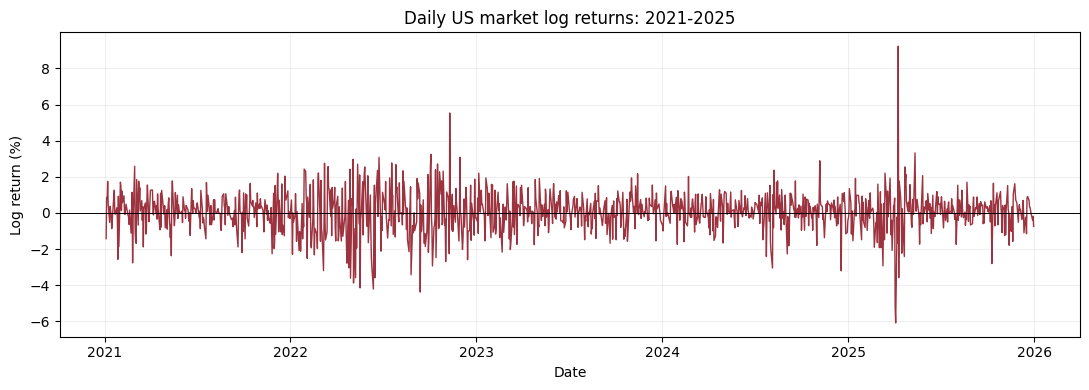

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(returns.index, returns, color="#9d333f", linewidth=1)
ax.axhline(0, color="black", linewidth=0.7)
ax.set(title="Daily US market log returns: 2021-2025", ylabel="Log return (%)", xlabel="Date")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

The size of daily movements varies across the sample. Quieter intervals and
clusters of large positive or negative returns concern the **magnitude** of
movements. They do not by themselves
establish correlation in their signs or prove that tomorrow's return can be
predicted from today's return. Keep all these observations in the analysis.

## The sample autocorrelation function

For a weakly stationary process, $\rho_k=\operatorname{Cov}(r_t,r_{t-k})/
\operatorname{Var}(r_t)$. Estimate it using the sample mean $\bar r$:

$$\widehat\rho_k=
\frac{\sum_{t=k+1}^{T}(r_t-\bar r)(r_{t-k}-\bar r)}
{\sum_{t=1}^{T}(r_t-\bar r)^2},\qquad k=1,\ldots,15.$$

Lag zero is always 1 and is omitted. A positive lag-one autocorrelation indicates
same-direction linear association across adjacent sessions; a negative value
indicates reversal. The shaded bands below use the approximate white-noise
reference $\pm1.96/\sqrt T$. They are **pointwise** bands, not a simultaneous
95% statement about all 15 lags. Some crossings can occur by chance when many
lags are inspected. Their usual calibration also assumes a suitable white-noise
reference; conditional heteroskedasticity can affect it.

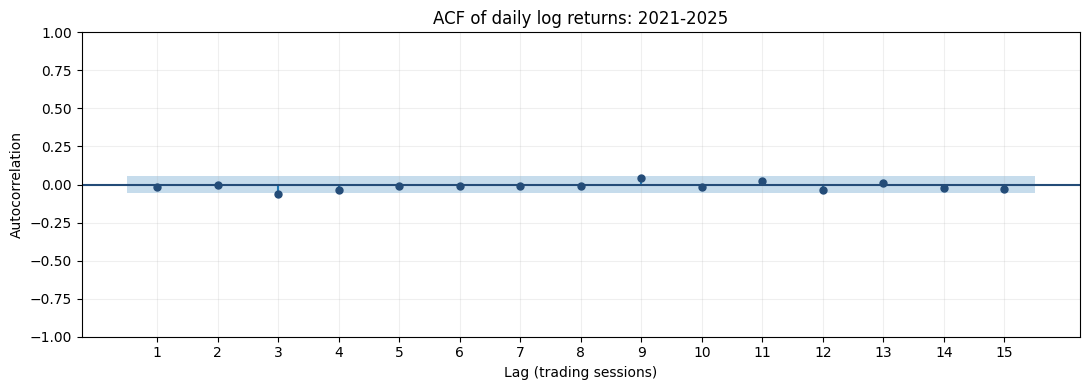

,Sample ACF
Lag,
1,-0.0149
2,0.0000
3,-0.0631
4,-0.0366
5,-0.0095


In [5]:
MAX_LAG = 15
sample_acf = acf(returns, nlags=MAX_LAG, fft=False, adjusted=False)
fig, ax = plt.subplots(figsize=(11, 4))
plot_acf(returns, lags=MAX_LAG, zero=False, alpha=0.05,
         bartlett_confint=False, ax=ax, color="#244c78")
ax.set(title="ACF of daily log returns: 2021-2025", xlabel="Lag (trading sessions)", ylabel="Autocorrelation")
ax.set_xticks(range(1, MAX_LAG + 1))
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
display(pd.DataFrame({"Lag": range(1, 6), "Sample ACF": sample_acf[1:6]}).set_index("Lag").round(4))

## Testing the first five autocorrelations jointly

The Ljung-Box test addresses a joint hypothesis:

$$H_0:\rho_1=\rho_2=\cdots=\rho_5=0,\qquad
H_1:\text{at least one of these autocorrelations differs from zero}.$$

For $m=5$, the statistic is

$$Q(m)=T(T+2)\sum_{k=1}^{m}\frac{\widehat\rho_k^2}{T-k}.$$

Under the usual null assumptions, $Q(5)$ is approximately $\chi^2_5$.
No AR or MA parameters have been fitted to these returns, so no fitted-model
degrees-of-freedom adjustment is made. Use $\alpha=0.05$ and specify five lags
before reading the results. The p-value is the null-reference probability of a
statistic at least as large as the observed value; it is not the probability
that the null is true.

The usual chi-square calibration is a teaching approximation. Strong changing
volatility can distort its size; do not treat this as a
heteroskedasticity-robust test or a definitive market-efficiency result.

In [6]:
TEST_LAG = 5
ALPHA = 0.05
lb = acorr_ljungbox(returns, lags=[TEST_LAG], model_df=0, return_df=True)
q_manual = len(returns) * (len(returns) + 2) * np.sum(
    sample_acf[1:TEST_LAG + 1] ** 2 / (len(returns) - np.arange(1, TEST_LAG + 1))
)
p_manual = stats.chi2.sf(q_manual, df=TEST_LAG)
test_summary = pd.DataFrame({"Q(5)": [q_manual], "Reference df": [5], "p-value": [p_manual],
                             "Decision at 5%": ["Reject H0" if p_manual < ALPHA else "Do not reject H0"]},
                            index=["2021-2025"])
display(test_summary.style.format({"Q(5)": "{:.4f}", "p-value": "{:.3g}"}))

,Q(5),Reference df,p-value,Decision at 5%
2021-2025,7.0970,5,0.214,Do not reject H0


For 2021-2025, $Q(5)=7.097$ and the p-value is approximately **0.214**:
do not reject the joint null at 5%. The lag-one sample autocorrelation is about
**-0.015**, close to zero. There is insufficient evidence against zero
autocorrelation at all five tested lags under the test's assumptions.
This conclusion concerns the specified joint hypothesis, not every possible
lag or form of dependence.

A rejection is evidence against zero autocorrelation at all five tested lags
under the test's assumptions. It does not identify a profitable trading rule,
establish causality, or measure out-of-sample forecast performance. A failure
to reject means insufficient evidence at these lags; it does not prove
independence, rule out nonlinear dependence, or establish market efficiency.

Autocorrelation describes linear dependence. Even zero autocorrelation at
every nonzero lag would not generally imply independent observations.

## Dependence in return magnitudes

As a short extension, compare returns with **squared demeaned returns**,
$(r_t-\bar r)^2$. Squared returns are commonly used as a **proxy for conditional
variance**, or volatility squared, when the conditional mean is close to zero.
Writing $\mu_t=E[r_t\mid\mathcal F_{t-1}]$ and
$\sigma_t^2=\operatorname{Var}(r_t\mid\mathcal F_{t-1})$ gives

$$E[r_t^2\mid\mathcal F_{t-1}]=\sigma_t^2+\mu_t^2
\approx\sigma_t^2\quad\text{when }\mu_t\approx0.$$

Here $\mathcal F_{t-1}$ denotes information available before the return is
observed. The relevant assumption concerns the **conditional mean**, not just
a zero overall sample mean. Strictly, volatility is the conditional standard
deviation $\sigma_t$; squared returns proxy $\sigma_t^2$.

The notebook subtracts the small sample mean before squaring. This produces a
similar proxy to $r_t^2$, but does not estimate a time-varying conditional mean.
Each squared return is a noisy observation, rather than the conditional
variance itself. Its autocorrelations can remain large even when those of
signed returns are small, indicating persistence in the size of movements.

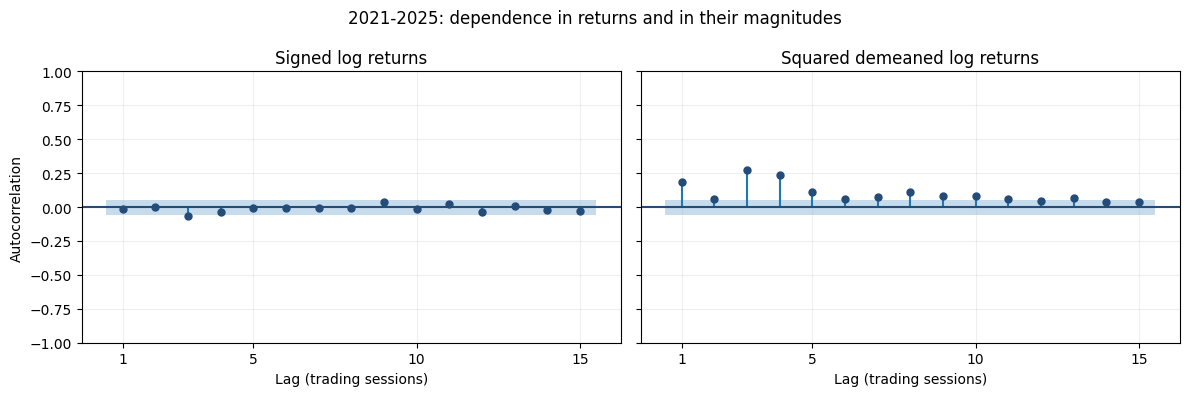

In [7]:
squared_returns = (returns - returns.mean()) ** 2
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, values, title in zip(axes, [returns, squared_returns],
                             ["Signed log returns", "Squared demeaned log returns"]):
    plot_acf(values, lags=MAX_LAG, zero=False, alpha=0.05,
             bartlett_confint=False, ax=ax, color="#244c78")
    ax.set(title=title, xlabel="Lag (trading sessions)")
    ax.set_xticks([1, 5, 10, 15])
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Autocorrelation")
fig.suptitle("2021-2025: dependence in returns and in their magnitudes")
fig.tight_layout()
plt.show()

The squared-return panel helps explain why a series can have changing,
persistent volatility without equally persistent linear dependence in returns.
It is a descriptive comparison; modelling that volatility is left for a later
tutorial. The ACF bands and Ljung-Box p-values should be interpreted with the
assumptions stated above.